# 2026F - San Jose State University - CMPE-257 - project - Chris Carl

## Metadata
<div style="display: inline-block">
<!-- get the table rendered to the left rather than default center, the spaces after the raw html are important for markdown https://stackoverflow.com/a/78525025 -->

| Key | Value |
| :--- | :--- |
| author | Chris Carl(mailto:chris.carl@sjsu.edu) |
| date | 2026-11-13 |
| dataset | [AmesHousing.txt, save as CSV](https://jse.amstat.org/v19n3/decock/AmesHousing.txt) © 2015 American Statistical Association |

<!-- get the table rendered to the left rather than default center, the spaces after the raw html are important for markdown https://stackoverflow.com/a/78525025 -->
</div>

<!--
commands:
    ipynb CMPE-257/assignments/project/project.ipynb  # chriscarl.tools.documents
-->


# Abstract

This is my submission of project of CMPE-257 at SJSU instructed by Dr. Zara Hajihashemi in Fall 2026.

Explain the executive summary and findings. You HAVE TO. this is the first thing they see.


# TOC


<!-- # SUGGESTED TOC ORGANIZATION

# Project
# Abstract
# Table of Contents
# Question
# Answer
# Solution
## Background
## The Plan
## Code - Environment
## Code - Setup
## Code - Functions
## Code - Main
# Post Mortem
## Caveats
## Improvements
## Replication
# Appendix
## Criterion
## Changelog
-->

# Solution


## Code - Setup

The following is boilerplate I've accumulated over the years and can be safely disregarded by the reader until it becomes relevant as part of deeper inquiry.


In [1]:
# stdlib imports
import __main__
import os
import sys
import pprint
import importlib
import subprocess
# hyper-critical imports
try:
    from IPython import get_ipython
    IPYTHON_SHELL = get_ipython()  # None if running in vanilla python
except ImportError:
    IPYTHON_SHELL = None

SCRIPT_FILEPATH = ''
SCRIPT_FILENAME = ''
if IPYTHON_SHELL:
    SCRIPT_DIRPATH = str(IPYTHON_SHELL.run_line_magic('pwd', ' # %pwd is a "magic" command  https://ipython.readthedocs.io/en/stable/interactive/magics.html'))
    if hasattr(__main__, '__vsc_ipynb_file__'):  # vscode
        SCRIPT_FILEPATH = __main__.__vsc_ipynb_file__
    elif hasattr(__main__, '__session__'):  # localhost:8888/notebooks
        SCRIPT_FILEPATH = __main__.__session__
else:
    SCRIPT_FILEPATH = __file__
    SCRIPT_DIRPATH = os.path.dirname(SCRIPT_FILEPATH)

SCRIPT_FILENAME = os.path.splitext(os.path.basename(SCRIPT_FILEPATH))[0]

pprint.pprint(dict(dir=SCRIPT_DIRPATH, fp=SCRIPT_FILEPATH, fn=SCRIPT_FILENAME), indent=2)

AUTO_INSTALL = False
packages = {'imbalanced-learn': 'imblearn'}  # {'Werkzeug': 'werkzeug'}  # package name: module name
modules = ['matplotlib', 'pandas', 'ipykernel', 'ipympl', 'ipywidgets']
packages.update({m: m for m in modules})
package, module = '', ''
install_string = ' '.join(packages)
try:
    for package, module in packages.items():
        importlib.import_module(module)
except ImportError:
    print(f'"pip install {package}"', file=sys.stderr)
    if AUTO_INSTALL:
        %pip install {install_string}
    else:
        raise

# third party imports
import matplotlib.pyplot as plt

EXES = {
    'pandoc': {'exists': False},
    'latex': {'exists': False, 'win32': 'miktex', 'linux': 'texlive'},
}

for exe, data in EXES.items():
    if IPYTHON_SHELL:
        if sys.platform == 'win32':
            _res = !where.exe {exe}
            _exists = not _res[0].startswith('INFO')
        else:
            _res = !which {exe}
            _exists = bool(_res)
    else:
        if sys.platform == 'win32':
            _res = subprocess.check_output(f'where.exe {exe}', universal_newlines=True)
            _exists = not _res.startswith('INFO')
        else:
            _res = subprocess.check_output(f'which {exe}', universal_newlines=True)
            _exists = bool(_res)
    EXES[exe]['exists'] = _exists

print('pandoc:', EXES['pandoc']['exists'])
if not EXES['pandoc']['exists']:
    print('you must install pandoc!', file=sys.stderr)
    if sys.platform == 'win32':
        print('    choco install pandoc -y', file=sys.stderr)
    else:
        print('    sudo apt install pandoc -y', file=sys.stderr)
        print('    sudo yum install pandoc -y', file=sys.stderr)
        print('    dnf install pandoc -y', file=sys.stderr)
    raise RuntimeError()

print('latex:', EXES['latex']['exists'])
plt.rcParams.update(
    {
        'text.usetex': EXES['latex']['exists'],  # , 'font.family': 'Helvetica'  # requires latex installed
        'text.latex.preamble': r'\usepackage{amsmath}',  # https://stackoverflow.com/a/23856968  \text command
    }

)

# command to tell the notebook to plt.show() IN THE NOTEBOOK, otherwise you call plt.show()
%matplotlib inline
# command to tell the notebook to render interactable matplotlib, requires pip install ipympl
# %matplotlib widget

print('# pip install', install_string)
if not IPYTHON_SHELL:
    raise RuntimeError('Not sure how, but somehow this code is being run through a non-iPython environment!')


{ 'dir': 'c:\\Users\\chris\\src\\sjsu.CMPE-257.ml-social-bot-detection\\src',
  'fn': 'project',
  'fp': 'c:\\Users\\chris\\src\\sjsu.CMPE-257.ml-social-bot-detection\\src\\project.ipynb'}
pandoc: True
latex: True
# pip install imbalanced-learn matplotlib pandas ipykernel ipympl ipywidgets


# Setup

In [2]:
PROJECT_DIRPATH = os.path.abspath(os.path.join(SCRIPT_DIRPATH, '..'))
DATA_DIRPATH = os.path.join(PROJECT_DIRPATH, 'ignoreme/data')
CRESCI_17_DIRPATH = os.path.join(DATA_DIRPATH, 'cresci-17')
TWIBOT_22_DIRPATH = os.path.join(DATA_DIRPATH, 'twibot-22')
LIKELIHOOD_PDF_FILEPATH = os.path.join(DATA_DIRPATH, 'likelihood-pdf.pkl')
DATASET_DIRECTORIES = [
    CRESCI_17_DIRPATH,
    TWIBOT_22_DIRPATH,
]
RANDOM_STATE = 42
ILOCS_ILIKE = [1, 13, 69, 420]


In [3]:
import os
import zipfile

def unzip_file(zip_path, extract_to, password=None, print_progress=True):
    if not os.path.isfile(zip_path):
        raise FileNotFoundError(f"ZIP file not found: {zip_path}")
    os.makedirs(extract_to, exist_ok=True)
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            pwd = password.encode() if password else None
            for member in zip_ref.infolist():
                # Prevent Zip Slip vulnerability
                extracted_path = os.path.join(extract_to, member.filename)
                if member.filename.startswith('__MACOSX/._') or member.filename.split('/')[-1].startswith('._'):
                    continue

                if not os.path.realpath(extracted_path).startswith(os.path.realpath(extract_to)):
                    raise Exception(f"Unsafe file path detected: {member.filename}")

                if print_progress:
                    print(member)
                if not os.path.exists(extracted_path):
                    zip_ref.extract(member, path=extract_to, pwd=pwd)

                basename, ext = os.path.splitext(member.filename)

                if ext == '.zip':
                    unzip_file(os.path.join(extract_to, member.filename), os.path.join(extract_to, basename), password=password, print_progress=print_progress)
    except zipfile.BadZipFile:
        raise zipfile.BadZipFile(f"Invalid ZIP file: {zip_path}")
    except RuntimeError as e:
        if "password required" in str(e).lower():
            raise RuntimeError("This ZIP file is password-protected. Please provide a valid password.")
        else:
            raise


In [4]:
ZIPS = [
    os.path.join(CRESCI_17_DIRPATH, 'datasets_full.csv.zip'),
]
for file in ZIPS:
    basename, _ = os.path.splitext(file)
    unzip_file(file, basename)


<ZipInfo filename='datasets_full.csv/' filemode='drwxr-xr-x' external_attr=0x10>
<ZipInfo filename='datasets_full.csv/crowdflower_results.csv.zip' compress_type=deflate filemode='-rw-r--r--' external_attr=0x4000 file_size=290528 compress_size=289584>
<ZipInfo filename='crowdflower_results.csv/' filemode='drwxr-xr-x' external_attr=0x4000>
<ZipInfo filename='crowdflower_results.csv/crowdflower_results_aggregated.csv' compress_type=deflate filemode='-rw-r--r--' external_attr=0x4000 file_size=617235 compress_size=107077>
<ZipInfo filename='__MACOSX/' filemode='drwxrwxr-x' external_attr=0x4000>
<ZipInfo filename='__MACOSX/crowdflower_results.csv/' filemode='drwxrwxr-x' external_attr=0x4000>
<ZipInfo filename='crowdflower_results.csv/crowdflower_results_contributors.csv' compress_type=deflate filemode='-rw-r--r--' external_attr=0x4000 file_size=24118 compress_size=8227>
<ZipInfo filename='crowdflower_results.csv/crowdflower_results_detailed.csv' compress_type=deflate filemode='-rw-r--r--' ex

In [5]:
import multiprocessing
import concurrent.futures
from typing import Callable, Any

MAX_WORKERS = multiprocessing.cpu_count() - 1

def parallel(funcs, args, kwargs, key=lambda args: args[0], max_workers=MAX_WORKERS):
    # type: (list[Callable], list[tuple], list[dict], Callable, int) -> list[tuple[Any, Any|Exception]]
    # https://docs.python.org/3/library/concurrent.futures.html
    N = len(funcs)
    if len(funcs) != len(args) or len(args) != len(kwargs):
        raise ValueError('need to provide same list amount of funcs, args, kwargs')

    res = []
    # NOTE: to run this, you need to use external files for the functions you have in mind
    with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
        future_to_ret = {executor.submit(funcs[i], *args[i], **kwargs[i]): key(args[i]) for i in range(len(args))}
        for f, future in enumerate(concurrent.futures.as_completed(future_to_ret)):
            arg = future_to_ret[future]
            try:
                data = future.result()
            except Exception as exc:
                print(f'{f+1} / {N} - FAILURE! {arg}: {exc}', file=sys.stderr)
                res += [(arg, exc)]
            else:
                print(f'{f+1} / {N} - SUCCESS! {arg}: {data}', file=sys.stdout)
                res += [(arg, data)]
    return res


In [6]:
%%writefile data_to_pickle.py
import os
import pickle
import warnings
import pandas as pd

def data_to_pickle(filepath, pickle_filepath, skip_exists=False):
    # type: (str, str) -> list[tuple[str, str]]
    changed_columns = []
    if not skip_exists and os.path.isfile(pickle_filepath) and os.path.getsize(filepath) / os.path.getsize(pickle_filepath) > 0.3:
        changed_columns += [('pickle', 'exists')]
        return changed_columns

    ext = os.path.splitext(filepath)[1]
    if ext.lower() == '.json':
        try:
            df = pd.read_json(filepath, dtype=str, encoding='utf-8', orient='records')
        except UnicodeDecodeError:
            df = pd.read_json(filepath, dtype=str, encoding='latin-1', orient='records')
    elif ext.lower() == '.csv':
        try:
            df = pd.read_csv(filepath, dtype=str, encoding='utf-8', low_memory=False)
        except UnicodeDecodeError:
            df = pd.read_csv(filepath, dtype=str, encoding='latin-1', low_memory=False)
    else:
        raise NotImplementedError(f'no parser implemented for {ext.lower()!r}')

    for col in df.columns:
        if df[col].nunique() < 69:
            df[col] = df[col].astype('category')
            changed_columns.append((col, 'category'))
            continue


        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            try:
                    df[col] = pd.to_numeric(df[col])
                    changed_columns.append((col, 'int/float'))
                    continue
            except Exception:
                pass

            try:
                    df[col] = pd.to_datetime(df[col])
                    changed_columns.append((col, 'datetime'))
                    continue  # useless, but keeps the pattern
            except Exception:
                pass

    with open(pickle_filepath, 'wb') as f:
        pickle.dump(df, f)

    return changed_columns

Overwriting data_to_pickle.py


In [7]:
import os
import glob
import pandas as pd
from data_to_pickle import data_to_pickle


funcs, args, kwargs = [], [], []
data_to_pickle_filepaths = {}
for d, dataset_directory in enumerate(DATASET_DIRECTORIES):
    globs = list(glob.glob(os.path.join(dataset_directory, '**', '*.csv'), recursive=True))
    globs += list(glob.glob(os.path.join(dataset_directory, '**', '*.json'), recursive=True))
    globs = sorted(globs, key=lambda pth: os.path.getsize(pth), reverse=True)  # complete in greatest to least
    for c, data_filepath in enumerate(globs):
        if not os.path.isfile(data_filepath):  # could be named datasets_full.csv...
            continue
        filename = os.path.splitext(data_filepath)[0]
        if os.path.getsize(data_filepath) > 4 * 1024 ** 3:  # > 4GB, not today, I dont need the hugest files
            continue

        pickle_filepath = f'{filename}.pkl'

        funcs += [data_to_pickle]
        args += [(data_filepath, pickle_filepath)]
        kwargs += [dict()]

        data_to_pickle_filepaths[data_filepath] = pickle_filepath

results = parallel(funcs, args, kwargs, key=lambda args: args[0], max_workers=6)

errors = []
original, pickled = 0, 0
for t, tpl in enumerate(results):
    data_filepath, result = tpl
    pickle_filepath = data_to_pickle_filepaths[data_filepath]
    print(f'{t+1} / {len(results)} - "{os.path.relpath(data_filepath, PROJECT_DIRPATH)}"')
    if isinstance(result, Exception):
        errors.append(data_filepath)
    else:
        original += os.path.getsize(data_filepath)
        pickled += os.path.getsize(pickle_filepath)

print(f'saved {((original - pickled) / original * 100):0.3f}% from {original / 1024**3:0.3f}GB to {pickled / 1024**3:0.3f}GB')
for error in errors:
    print(f'  - "{error}"')


1 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_1.csv\social_spambots_1.csv\tweets.csv: [('pickle', 'exists')]
2 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\users.csv: [('pickle', 'exists')]
3 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_3.csv\social_spambots_3.csv\tweets.csv: [('pickle', 'exists')]
4 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_2.csv\social_spambots_2.csv\users.csv: [('pickle', 'exists')]
5 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\fake_follower

22 / 24 - FAILURE! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\tweets.csv: Error tokenizing data. C error: Expected 26 fields in line 8, saw 27



"But no dataset can generalize well on all other datasets." - 1099
Basically, construct a random forest on one dataset, evaluate it on another dataset.

Basically, create an AUC table.
seperability - averaging across columns
generalizability - averaging across rows

They find no correlation between separability and generalizabilitty, r=0.18, p=0.6

AUC - area under ROC curve (plotting false positives as X vs true positives as Y), want close to 1.0

RandomForest 100 trees
5-fold CV

Chose a threshold, Different thresholds yield best ac-
curacy in cross-validation (F1 = 0 .94, R = 0 .93, P = 0 .94)
or cross-domain testing (F1 = 0 .77, R = 0 .68, P = 0 .88)

botometer is the baseline, Yang et al. 2019 - Yang, K.-C.; Varol, O.; Davis, C. A.; Ferrara, E.; Flammini, A.; and Menczer, F. 2019. Arming the public with artificial intelligence to counter social bots. Hum. Behav. and Emerg. Tech. 1(1):48–61.

Calculate SHAP value

[RapidAPI Botometer, see X-RapidAPI-Key after a playground post request](https://rapidapi.com/OSoMe/api/botometer-pro/playground/Botometer%20X)
https://github.com/osome-iu/botometer-python
https://onlinelibrary.wiley.com/doi/epdf/10.1002/hbe2.115


```python
import botometer
rapidapi_key = '2acd778cf3msh07109caf26fad9cp1d2f9ajsn334346a50893'
bomx = botometer.BotometerX(rapidapi_key=rapidapi_key)
bomx.get_botscores_in_batch(usernames=['@OSoMe_IU', 'botometer'])
[{'bot_score': 0.09, 'timestamp': 'Sat, 27 May 2023 23:57:16 GMT', 'user_id': '2451308594', 'username': 'Botometer'}, {'bot_score': 0.21, 'timestamp': 'Thu, 25 May 2023 22:54:53 GMT', 'user_id': '187521608', 'username': 'OSoMe_IU'}]
```

In [8]:
import sys
import pprint
import string
import math
import random
import pickle
from itertools import permutations

def dict_subset(dic, k=10):
    preview = {key: dic[key] for key in random.choices(list(dic.keys()), k=k)}
    return preview

# to create the lookup n-gram table
def n_gram_probabilities(text, grams, n):
    # type: (str, str, int) -> dict[str, float]
    pdf = {}
    for gram in grams:
        pdf[(gram,)*n] = 0
    for n_gram in permutations(grams, r=n):
        pdf[n_gram] = 0

    total_grams = len(text) - n
    for c in range(0, total_grams):
        n_gram = tuple(text[c:c+n])
        pdf[n_gram] += 1

    for k, v in pdf.items():
        pdf[k] = v / total_grams
        if pdf[k] == 0:
            pdf[k] = sys.float_info.min  # smallest non-zero float possible so logarithm doesnt get domain error

    return pdf


# use one the genuine accounts to bootstrap the PDF
df = pd.read_pickle(fr'{CRESCI_17_DIRPATH}\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\users.pkl')


GRAMS = string.ascii_letters + '0123456789_'  # '01234ABCDabcd'
N_GRAMS = 2
LIKELIHOOD_PDF = n_gram_probabilities(''.join(df['screen_name']), GRAMS, N_GRAMS)
pprint.pprint(dict_subset(LIKELIHOOD_PDF), indent=4)
del df

with open(LIKELIHOOD_PDF_FILEPATH, 'wb') as wb:
    pickle.dump(LIKELIHOOD_PDF, wb)


def likelihood(cell, n=2, pdf=LIKELIHOOD_PDF):
    # https://arxiv.org/pdf/1812.05932
    # Beskow and Carley 2019 - Beskow, D. M., and Carley, K. M. 2019. Its all in a name: detecting and labeling bots by their name. Comp. and Math. Org. Theory 1–12.
    # likelihood of a screen name is defined by the geometric-mean likelihood of all bigrams in it.
    # We collected over 2M unique screen names and constructed the likelihood of all 3,969 possible bigrams
    # geometric mean is \prod_{n-gram in n-grams of text} p_{n-gram}
    #   taking the log is just as effective instead of multiplying small probabilities.
    n_grams = [cell[c:c+n] for c in range(0, len(cell) - n)]
    if not n_grams:
        return sys.float_info.min
    total = len(n_grams)
    summand = sum(math.log(pdf[tuple(n_gram)]) for n_gram in n_grams)
    exp = math.exp(summand / total)
    return exp


print(f"cresci_17 likelihood: {likelihood('cresci_17') * 100:0.9f}%, high likelihood")
print(f"twibot_22 likelihood: {likelihood('twibot_22') * 100:0.9f}%, high likelihood")
random_username = ''.join(random.choices(GRAMS, k=15))
print(f"{random_username} likelihood: {likelihood(random_username) * 100:0.9f}%, low likelihood")


{   ('5', '8'): 0.00015899936400254398,
    ('C', 'X'): 2.2250738585072014e-308,
    ('L', 'q'): 2.2250738585072014e-308,
    ('M', '5'): 2.6499894000423998e-05,
    ('O', '0'): 2.2250738585072014e-308,
    ('P', 'V'): 2.6499894000423998e-05,
    ('X', 'u'): 2.2250738585072014e-308,
    ('Y', 'J'): 5.2999788000847996e-05,
    ('_', 'p'): 0.00023849904600381597,
    ('c', 'F'): 2.2250738585072014e-308}
cresci_17 likelihood: 0.153887449%, high likelihood
twibot_22 likelihood: 0.083157929%, high likelihood
eUwfQZfi8oBLEJ0 likelihood: 0.000000000%, low likelihood


In [9]:
import re
import numpy as np
import datetime
from collections import OrderedDict

FEATURE_TABLE = '''
feature                         type    calculation
---                             ---     ---
statuses_count                  count
followers_count                 count
friends_count                   count
favourites_count                count
listed_count                    count
default_profile                 binary
profile_use_background_image    binary
verified                        binary

user_age                        real    hour difference between probe time and creation time
tweet_freq                      real    statuses_count / user_age
followers_growth_rate           real    followers_count / user_age
friends_growth_rate             real    friends_count / user_age
favourites_growth_rate          real    favourites_count / user_age
listed_growth_rate              real    listed_count / user_age
followers_friends_ratio         real    followers_count / friends_count
screen_name_length              count   length of screen name string
num_digits_in_screen_name       count   no. digits in screen name string
name_length                     count   length of name string
num_digits_in_name              count   no. digits in name string
description_length              count   length of description string
screen_name_likelihood          real    likelihood of the screen name
'''

NANS = {np.nan, float('nan'), None}

def str_digits_len(cell):
    if cell in NANS:
        return 0
    else:
        try:
            return len(re.findall(r'\d', str(cell)))
        except TypeError:
            print(cell, type(cell))
            raise

def str_len(cell):
    if cell in NANS:
        return 0
    else:
        try:
            return len(cell)
        except TypeError:
            print(cell, type(cell))
            raise


FEATURES = OrderedDict([
    # no computation / known dtypes
    ('statuses_count', pd.to_numeric),
    ('followers_count', pd.to_numeric),
    ('friends_count', pd.to_numeric),
    ('favourites_count', pd.to_numeric),
    ('listed_count', pd.to_numeric),
    ('default_profile', bool),
    ('profile_use_background_image', bool),
    ('verified', bool),
    # computed - columnar, subtraction
    ('user_age', ('created_at', ('crawled_at', 'updated'), '-')),  # some don't have crawled at, try updated instead
    # computed - columnar, division
    ('tweet_freq', ('statuses_count', 'user_age', '/')),
    ('followers_growth_rate', ('followers_count', 'user_age', '/')),
    ('friends_growth_rate', ('friends_count', 'user_age', '/')),
    ('favourites_growth_rate', ('favourites_count', 'user_age', '/')),
    ('listed_growth_rate', ('listed_count', 'user_age', '/')),
    ('followers_friends_ratio', ('followers_count', 'friends_count', '/')),
    # computed - columnar, apply axis 0
    ('screen_name_length', ('screen_name', str_len)),
    ('num_digits_in_screen_name', ('screen_name', str_digits_len)),
    ('name_length', ('name', str_len)),
    ('num_digits_in_name', ('name', str_digits_len)),
    ('description_length', ('description', str_len)),
    ('screen_name_likelihood', ('screen_name', likelihood)),
])
KNOWN_FEATURES = OrderedDict([
    # no computation / known dtypes
    ('statuses_count', pd.to_numeric),
    ('followers_count', pd.to_numeric),
    ('friends_count', pd.to_numeric),
    ('favourites_count', pd.to_numeric),
    ('listed_count', pd.to_numeric),
    ('default_profile', bool),
    ('profile_use_background_image', bool),
    ('verified', bool),
    ('created_at', datetime.datetime),
    ('crawled_at', datetime.datetime),
    ('updated', datetime.datetime),

])
FEATURES_LIST = list(FEATURES)
TARGET = 'bot'



In [10]:
import numpy as np

def null_treatment(df):
    # null treatment
    for col in df.select_dtypes(include=['str']).columns:
        df[col] = df[col].fillna('')  # NOTE: OTHERWISE IT GETS EVALUATED AS A FLOAT, and you can't .apply(len) on it...
    for col in df.select_dtypes(include=['object'], exclude=['str']).columns:
        if set(df[col].unique()) == {np.nan, True}:
            df[col] = df[col].astype(bool)
    for col in df.select_dtypes(include=[bool]).columns:
        df[col] = df[col].fillna(False)
    for col in df.select_dtypes(include=[int, float]).columns:
        df[col] = df[col].replace([np.inf, -np.inf], np.nan)
        df[col] = df[col].fillna(df[col].mean())

    return df


In [11]:
import datetime

def preprocess(filepath):
    # https://stackoverflow.com/a/51460999
    print(f'preprocessing "{filepath}"')
    df = pd.read_pickle(filepath)

    for col, astype in KNOWN_FEATURES.items():
        if col in df.columns:
            try:
                if astype is pd.to_numeric:
                    df[col] = pd.to_numeric(df[col])
                elif astype is bool:
                    df[col] = df[col].astype(bool)
                elif astype is datetime.datetime:
                    if df[col].dtype == 'str':
                        if df[col].iloc[0].endswith('L'):
                            df[col] = pd.to_datetime(df[col].str.rstrip('L'), unit='s', errors='coerce')

                    df[col] = pd.to_datetime(df[col])
                    if df[col].dt.tz is None:
                        df[col] = df[col].dt.tz_localize(datetime.timezone.utc)
            except Exception:
                print(f'ERROR: failed on converting {col} -> {astype}')
                display(df[col])
                raise

    # null treatment
    df = null_treatment(df)

    # python / pandas / framework idiosyncracies
    for col in df.select_dtypes(include=['datetime64']).columns:
        df[col] = df[col].dt.tz_localize(datetime.timezone.utc)

    # feature engineering
    failed_apply = []
    # df[[col for col in df.columns if col in FEATURES]].info()
    for feature, tpl in FEATURES.items():
        try:
            # print(feature, tpl)
            if tpl is None:
                continue
            elif isinstance(tpl, type):
                typ = tpl
                df[feature] = df[feature].astype(typ)
            elif callable(tpl):
                func = tpl
                df[feature] = func(df[feature])
            elif isinstance(tpl, tuple):
                if len(tpl) == 3:
                    left, right, op = tpl
                    if isinstance(right, tuple):  # options in case the right side is missing
                        found = False
                        for right in tpl[1]:
                            if right not in df.columns:
                                continue
                            found = True
                            break

                        if not found:
                            raise NotImplementedError(f'couldnt find any of the intended replacements for right side of {left}: {tpl[1]}')

                    if op == '/':
                        df[feature] = df[left] / df[right]
                    elif op == '-':
                        df[feature] = (df[right] - df[left]).dt.total_seconds() / 3600
                    else:
                        raise NotImplementedError(f'{feature, tpl}')
                elif callable(tpl[1]):
                    left, func = tpl
                    df[feature] = df[left].apply(func)  # NOTE: do not do axis=0, causes it to be hit with extra kwargs...
                else:
                    raise NotImplementedError(f'{feature, tpl}')
            else:
                raise NotImplementedError(f'{feature, tpl}')
        except Exception:
            print(f'ERROR: failed on creating {tpl}')
            print(f'    target column: {left}')
            display(df[left])
            raise

    # null treatment
    df = null_treatment(df)
    # df[[col for col in df.columns if col in FEATURES]].info()

    assert not failed_apply, f'"{filepath}" failed to apply: {failed_apply}'
    return df

# df = preprocess(r'c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_2.csv\social_spambots_2.csv\users.pkl')
# df[FEATURES_LIST]

# for d, _, fs in os.walk(CRESCI_17_DIRPATH):
#     for f in fs:
#         if f == 'users.pkl':
#             filepath = os.path.join(d, f)
#             df = preprocess(filepath)


In [12]:
# demonstrate preprocessing, will do full thing later
df0 = preprocess(fr'{CRESCI_17_DIRPATH}\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\users.pkl')
df0['bot'] = 0
df1 = preprocess(fr'{CRESCI_17_DIRPATH}\datasets_full.csv\datasets_full.csv\social_spambots_1.csv\social_spambots_1.csv\users.pkl')
df1['bot'] = 1

display(df0.loc[[69, 690], FEATURES_LIST])
display(df1.loc[[69, 690], FEATURES_LIST])
df = pd.concat([df0, df1])
# del df0, df1
print('nulls:', df[FEATURES_LIST].isna().sum().sum())
df[FEATURES_LIST].info(memory_usage='deep')


preprocessing "c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\users.pkl"
preprocessing "c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_1.csv\social_spambots_1.csv\users.pkl"


,statuses_count,followers_count,friends_count,favourites_count,listed_count,default_profile,profile_use_background_image,verified,user_age,tweet_freq,...,friends_growth_rate,favourites_growth_rate,listed_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood
69,2287,71,56,295,3,True,True,True,47455.079722,0.048193,...,0.001180,0.006216,0.000063,1.267857,9,0,13,0,77,0.001664
690,6643,373,1716,1052,4,True,True,True,35377.578611,0.187774,...,0.048505,0.029736,0.000113,0.217366,8,0,10,0,22,0.000840


,statuses_count,followers_count,friends_count,favourites_count,listed_count,default_profile,profile_use_background_image,verified,user_age,tweet_freq,...,friends_growth_rate,favourites_growth_rate,listed_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood
69,128,222,294,0,0,True,True,True,20943.568611,0.006112,...,0.014038,0.0,0.0,0.755102,15,0,16,0,66,0.003503
690,139,1,0,0,0,True,True,True,19285.873611,0.007207,...,0.000000,0.0,0.0,6.437135,12,0,13,0,86,0.002707


nulls: 0
<class 'pandas.DataFrame'>
Index: 4465 entries, 0 to 990
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   statuses_count                4465 non-null   int64  
 1   followers_count               4465 non-null   int64  
 2   friends_count                 4465 non-null   int64  
 3   favourites_count              4465 non-null   int64  
 4   listed_count                  4465 non-null   int64  
 5   default_profile               4465 non-null   bool   
 6   profile_use_background_image  4465 non-null   bool   
 7   verified                      4465 non-null   bool   
 8   user_age                      4465 non-null   float64
 9   tweet_freq                    4465 non-null   float64
 10  followers_growth_rate         4465 non-null   float64
 11  friends_growth_rate           4465 non-null   float64
 12  favourites_growth_rate        4465 non-null   float64
 13  listed_grow

In [13]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

X = df[FEATURES_LIST]
X = pd.get_dummies(X, columns=X.select_dtypes(include=['object', bool]).columns.tolist(), drop_first=False).astype(float)
y = df[TARGET]
TARGET_NAMES = [f'{klass}' for klass in y.unique()]

# train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
scaler = StandardScaler()  # some need it, some dont
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [14]:
from sklearn.tree import plot_tree

def plot_random_forest(rfc, first=5):
    # https://stackoverflow.com/a/61037626
    fig, axes = plt.subplots(nrows=1, ncols=first, figsize=(10,2), dpi=900)
    for index in range(0, first):
        plot_tree(
            rfc.estimators_[index],
            feature_names=FEATURES_LIST,
            class_names=TARGET_NAMES,
            filled = True,
            ax = axes[index]
        )
        axes[index].set_title('Estimator: ' + str(index), fontsize = 11)
    fig.tight_layout()
    plt.show()
    # fig.savefig('rf_5trees.png')


def visualize_random_forest_important_features(rfc):
    importances = rfc.feature_importances_
    plt.figure(figsize=(10, 6))
    plt.barh(FEATURES_LIST, importances, color='skyblue')
    plt.xlabel("Feature Importance Score")
    plt.title("Random Forest - Feature Importances")
    plt.gca().invert_yaxis() # Highest importance at the top
    plt.show()


Accuracy: 0.99

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1053
           1       1.00      0.94      0.97       287

    accuracy                           0.99      1340
   macro avg       0.99      0.97      0.98      1340
weighted avg       0.99      0.99      0.99      1340



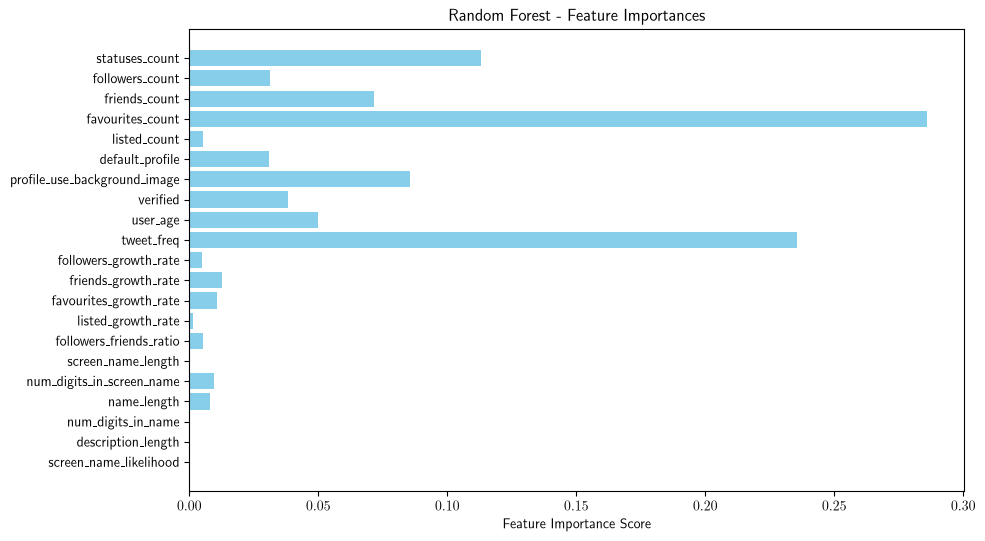

In [15]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rfc.fit(X_train, y_train)

y_hat = rfc.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_hat):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_hat, target_names=TARGET_NAMES))

visualize_random_forest_important_features(rfc)


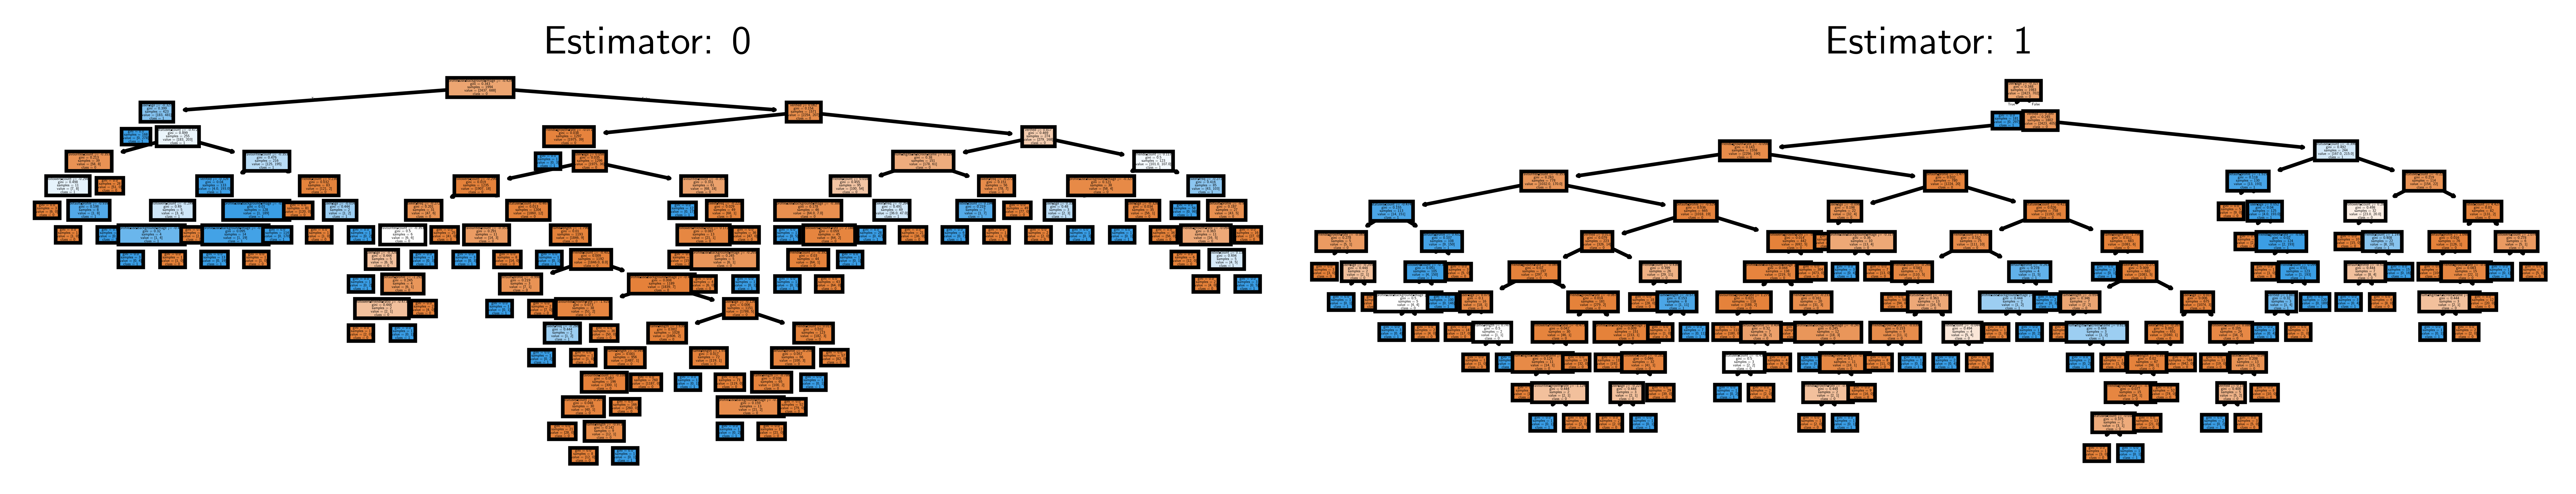

In [16]:
plot_random_forest(rfc, first=2)  # time consuing, may take > 1m

Accuracy: 0.99

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1053
           1       1.00      0.94      0.97       287

    accuracy                           0.99      1340
   macro avg       0.99      0.97      0.98      1340
weighted avg       0.99      0.99      0.99      1340



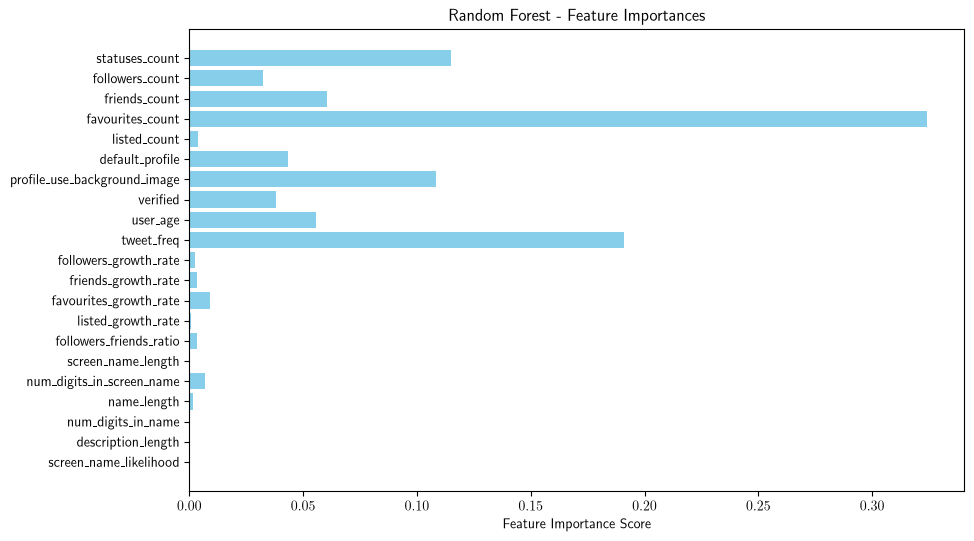

In [17]:
rfc_pre_pruned = RandomForestClassifier(n_estimators=50, max_depth=3, random_state=RANDOM_STATE)
rfc_pre_pruned.fit(X_train, y_train)

y_hat = rfc.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_hat):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_hat, target_names=TARGET_NAMES))

visualize_random_forest_important_features(rfc_pre_pruned)


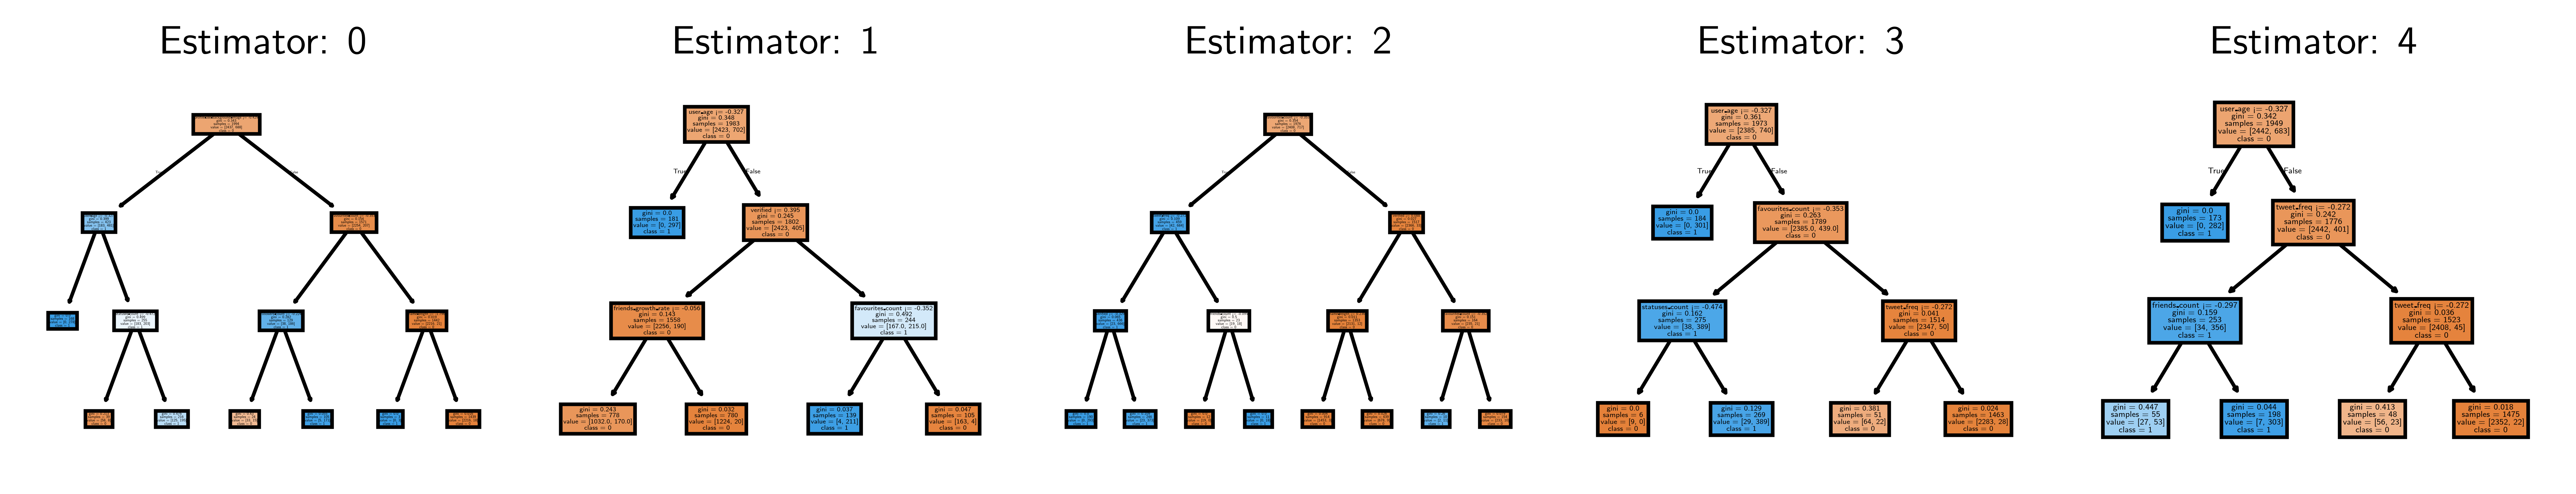

In [18]:
plot_random_forest(rfc_pre_pruned)

In [19]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=200, random_state=RANDOM_STATE)
lr.fit(X_train, y_train)  # prefer scaled

y_hat = lr.predict(X_test)  # prefer scaled
print(f"Accuracy: {accuracy_score(y_test, y_hat):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_hat, target_names=TARGET_NAMES))

print("Model Coefficients (Weights):")
coefficients = pd.DataFrame(lr.coef_, columns=FEATURES_LIST, index=[TARGET_NAMES[1]])  # for binary classification
display(coefficients)


Accuracy: 0.92

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      1053
           1       0.85      0.74      0.79       287

    accuracy                           0.92      1340
   macro avg       0.89      0.85      0.87      1340
weighted avg       0.91      0.92      0.91      1340

Model Coefficients (Weights):


,statuses_count,followers_count,friends_count,favourites_count,listed_count,default_profile,profile_use_background_image,verified,user_age,tweet_freq,...,friends_growth_rate,favourites_growth_rate,listed_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood
1,-2.989759,-0.580527,1.785687,-3.080668,-3.823443,-0.840846,-2.604119,0.218422,-0.211584,-3.82433,...,0.096965,0.824882,-0.539142,0.443453,-0.184553,0.059024,-0.033537,0.0,0.0,0.0


In [20]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE)
svm.fit(X_train, y_train)  # prefer scaled

y_hat = svm.predict(X_test)  # prefer scaled
print(f"Accuracy: {accuracy_score(y_test, y_hat):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_hat, target_names=TARGET_NAMES))


Accuracy: 0.96

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1053
           1       0.94      0.86      0.90       287

    accuracy                           0.96      1340
   macro avg       0.95      0.92      0.93      1340
weighted avg       0.96      0.96      0.96      1340



In [21]:
# from sklearn.tree import plot_tree

# # plot a decision tree
# plt.figure(figsize=(12, 8))
# plot_tree(
#     clf,
#     feature_names=FEATURES_LIST,
#     class_names=TARGET_NAMES,
#     filled=True,
#     rounded=True
# )
# plt.title("Decision Tree Visualization")
# plt.show()

## E2E Execution

todo:
    load up all user csvs
    load up twibot-22 user info

    balance the classes,
        random sample from each

    for dataset in dataset:
        train all of them
        evaluate against alternate dataset
        evaluate against botometer


In [22]:
DATASETS = OrderedDict([
    # to be altered
    ('cresci-17', (X_test, X_train, y_test, y_train)),
    ('twibot-22', (X_test, X_train, y_test, y_train)),
])
MODELS = OrderedDict([
    # to be altered
    ('cresci-17', (rfc, rfc_pre_pruned, lr, svm)),
    ('twibot-22', (rfc, rfc_pre_pruned, lr, svm)),
])


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.under_sampling import RandomUnderSampler

# process the cresci-17 dataset into a class balanced dataset, random sampling proportionally from each.
# onehot encode them
# create the splits and test set from each
cresci_17_df = pd.DataFrame()
for d, _, fs in os.walk(CRESCI_17_DIRPATH):
    for f in fs:
        if f == 'users.pkl':
            filepath = os.path.join(d, f)
            df = preprocess(filepath)

            if 'genuine_accounts' not in filepath:
                df['bot'] = 1
            else:
                df['bot'] = 0

            if not cresci_17_df.empty:
                cresci_17_df = pd.concat([cresci_17_df, df])
            else:
                cresci_17_df = df


preprocessing "c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\fake_followers.csv\fake_followers.csv\users.pkl"
preprocessing "c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\users.pkl"
preprocessing "c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_1.csv\social_spambots_1.csv\users.pkl"
preprocessing "c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_2.csv\social_spambots_2.csv\users.pkl"
preprocessing "c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme/data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_3.csv\social_spambots_3.csv\users.pkl"
preprocessing "c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\i

In [24]:
TWIBOT_DF_PROCESSED_FILEPATH = os.path.join(DATA_DIRPATH, 'twibot-22.pkl')

if not os.path.isfile(TWIBOT_DF_PROCESSED_FILEPATH):
    TWIBOT_DFS = {}
    for f in os.listdir(TWIBOT_22_DIRPATH):
        path = os.path.join(TWIBOT_22_DIRPATH, f)
        if not f.endswith('.pkl') or os.path.getsize(path) > 4 * 1024**3:
            continue
        df = pd.read_pickle(path)
        if 'id' not in df.columns:
            continue  # dont need it, like edge.pkl
        TWIBOT_DFS[f] = df  # .set_index('id')

    # list.pkl is too small, also doesn't share any commonality
    twibot_22_df = TWIBOT_DFS['user.pkl'].merge(TWIBOT_DFS['label.pkl'], how='outer', left_on='id', right_on='id', suffixes=('', '_label'))
    public_metrics_df_filepath = os.path.join(TWIBOT_22_DIRPATH, 'public-metrics.pkl')
    if not os.path.isfile(public_metrics_df_filepath):
        public_metrics_series = twibot_22_df['public_metrics'].fillna('{}')
        public_metrics_series = public_metrics_series.apply(lambda x: eval(x) if x not in NANS else {})   # bunch of dictionaries as strings
        public_metrics_df = public_metrics_series.apply(pd.Series)  # explode these dictionaries into a new dataframe entirely
        public_metrics_df.to_pickle(public_metrics_df_filepath)
    else:
        public_metrics_df = pd.read_pickle(public_metrics_df_filepath)

    twibot_22_df = pd.concat([twibot_22_df, public_metrics_df], axis=1)  # combine them left to right as is

    entities_df_filepath = os.path.join(TWIBOT_22_DIRPATH, 'entities.pkl')
    if not os.path.isfile(entities_df_filepath):
        entities_series = twibot_22_df['entities'].fillna('{}')
        entities_series = entities_series.apply(eval)   # bunch of dictionaries as strings
        entities_df = entities_series.apply(pd.Series)  # explode these dictionaries into a new dataframe entirely
        entities_df.to_pickle(entities_df_filepath)
    else:
        entities_df = pd.read_pickle(entities_df_filepath)

    url_desc_df_filepath = os.path.join(TWIBOT_22_DIRPATH, 'url-desc.pkl')
    if not os.path.isfile(url_desc_df_filepath):
        url_series = entities_df['url'].fillna({})
        description_series = entities_df['description'].fillna('{}')

        url_df = url_series.apply(pd.Series)
        description_df = description_series.apply(pd.Series)
        with open(url_desc_df_filepath, 'wb') as wb:
            pickle.dump([url_df, description_df], wb)
    else:
        with open(url_desc_df_filepath, 'rb') as rb:
            url_df, description_df = pickle.load(rb)

    twibot_22_df = pd.concat([twibot_22_df, url_df, description_df], axis=1)  # combine them left to right as is
    twibot_22_df.to_pickle(TWIBOT_DF_PROCESSED_FILEPATH)
else:
    twibot_22_df = pd.read_pickle(TWIBOT_DF_PROCESSED_FILEPATH)


In [25]:
twibot_22_df['statuses_count'] = pd.to_numeric(twibot_22_df['tweet_count'])
twibot_22_df['follower_count'] = pd.to_numeric(twibot_22_df['following_count'])
twibot_22_df['friends_count'] = pd.to_numeric(twibot_22_df['followers_count'])
twibot_22_df['listed_count'] = pd.to_numeric(twibot_22_df['listed_count'])
twibot_22_df['profile_use_background_image'] = twibot_22_df['profile_image_url'].astype(bool)
twibot_22_df['verified'] = twibot_22_df['verified'].astype(bool)
oldest = min([datetime.datetime.fromtimestamp(os.stat(os.path.join(d, f)).st_mtime, tz=datetime.timezone.utc) for d, _, fs in os.walk(TWIBOT_22_DIRPATH) for f in fs])
created_at = pd.to_datetime(twibot_22_df['created_at'])
created_at = created_at.dt.tz_localize(datetime.timezone.utc)
twibot_22_df['user_age'] = (oldest - created_at).dt.total_seconds() // 3600
twibot_22_df['followers_growth_rate'] = twibot_22_df['followers_count'] / twibot_22_df['user_age']
twibot_22_df['friends_growth_rate'] = twibot_22_df['friends_count'] / twibot_22_df['user_age']
twibot_22_df['followers_friends_ratio'] = twibot_22_df['followers_count'] / twibot_22_df['friends_count']
twibot_22_df['screen_name_length'] = twibot_22_df['username'].apply(str_len)
twibot_22_df['num_digits_in_screen_name'] = twibot_22_df['username'].apply(str_digits_len)
twibot_22_df['name_length'] = twibot_22_df['name'].apply(str_len)
twibot_22_df['num_digits_in_name'] = twibot_22_df['name'].apply(str_digits_len)
twibot_22_df['description_length'] = twibot_22_df['description'].apply(str_len)
twibot_22_df['screen_name_likelihood'] = twibot_22_df['username'].apply(likelihood)
twibot_22_df['bot'] = twibot_22_df['label'].astype(str).replace({'human': False, 'bot': True}).astype(bool)


In [26]:
twibot_22_df.info()
twibot_22_df.iloc[ILOCS_ILIKE]

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 41 columns):
 #   Column                        Non-Null Count    Dtype   
---  ------                        --------------    -----   
 0   created_at                    1000000 non-null  int64   
 1   description                   1000000 non-null  str     
 2   entities                      630750 non-null   str     
 3   id                            1000000 non-null  str     
 4   location                      708458 non-null   str     
 5   name                          1000000 non-null  str     
 6   pinned_tweet_id               389865 non-null   float64 
 7   profile_image_url             1000000 non-null  str     
 8   protected                     1000000 non-null  category
 9   public_metrics                1000000 non-null  str     
 10  url                           1000000 non-null  str     
 11  username                      1000000 non-null  str     
 12  verified                  

,created_at,description,entities,id,location,name,pinned_tweet_id,profile_image_url,protected,public_metrics,...,followers_growth_rate,friends_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood,bot
1,1527253955000000,Building an immune compendium #immunology,"{'description': {'hashtags': [{'start': 30, 'e...",u1000001683005542402,"Paris, France",ImmunoSCOPE,NaN,https://pbs.twimg.com/profile_images/100000721...,False,"{'followers_count': 7314, 'following_count': 1...",...,0.015950,0.015950,1.0,11,0,11,0,41,1.188173e-03,False
13,1527257557000000,,"{'url': {'urls': [{'start': 0, 'end': 23, 'url...",u1000016792205582336,"New Delhi, India",Mayank Vatsa,NaN,https://pbs.twimg.com/profile_images/100002462...,False,"{'followers_count': 418, 'following_count': 37...",...,0.000912,0.000912,1.0,12,1,12,0,0,8.347082e-34,True
69,1527277352000000,Sub specie aeternitatis. Marmara Üniversitesi ...,NaN,u1000099817819918341,"İstanbul, Türkiye",aykutozkan,1.007498e+18,https://pbs.twimg.com/profile_images/125749301...,False,"{'followers_count': 85, 'following_count': 454...",...,0.000185,0.000185,1.0,12,0,10,0,56,8.471001e-04,False
420,1527450011000000,Book snark. Sarcasm. Writing. Now on twitter! :D,"{'url': {'urls': [{'start': 0, 'end': 23, 'url...",u1000824004393881600,Goblin Kingdom,percontation-points,NaN,https://pbs.twimg.com/profile_images/145556773...,False,"{'followers_count': 24, 'following_count': 78,...",...,0.000052,0.000052,1.0,13,0,19,0,48,2.955931e-03,False


In [27]:
FEATURES_LIST_COMMON = [feature for feature in FEATURES_LIST if feature in cresci_17_df.columns and feature in twibot_22_df]


def encode_train_test_split_scale_sample(df, feature_list, target_name, random_state=RANDOM_STATE, sampling_strategy=0.5):
    X = df[feature_list]

    # encode
    X = pd.get_dummies(X, columns=X.select_dtypes(include=['object', bool]).columns.tolist(), drop_first=False).astype(float)
    X = X.fillna(0)  # final chance, some nan still sneaks through thanks to to_datetime errors='coerce'
    y = df[target_name]

    # split, scale, undersample
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
    scaler = StandardScaler()  # some need it, some dont
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    X_train, y_train = RandomUnderSampler(random_state=random_state, sampling_strategy=sampling_strategy).fit_resample(X_train, y_train)

    return X_train, X_test, y_train, y_test


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

def train_models(X_train, y_train, random_state=RANDOM_STATE):
    rfc = RandomForestClassifier(n_estimators=100, random_state=random_state)
    print(f'1/4 - training {rfc}')
    rfc.fit(X_train, y_train)

    rfc_pre_pruned = RandomForestClassifier(n_estimators=50, max_depth=3, random_state=random_state)
    print(f'2/4 - training {rfc_pre_pruned}')
    rfc_pre_pruned.fit(X_train, y_train)

    lr = LogisticRegression(max_iter=200, random_state=random_state)
    print(f'3/4 - training {lr}')
    lr.fit(X_train, y_train)  # prefer scaled

    svm = SVC(kernel='rbf', C=1.0, random_state=random_state)
    print(f'4/4 - training {svm}')
    svm.fit(X_train, y_train)  # prefer scaled

    return rfc, rfc_pre_pruned, lr, svm


In [29]:
# everything finished within 5 mins, SVC took the rest of the time, 32mins on 9950X3D
DATASETS_MODELS_FILEPATH = os.path.join(DATA_DIRPATH, 'datasets-models.pkl')

if os.path.isfile(DATASETS_MODELS_FILEPATH):
    print('loading datasets and models')
    with open(DATASETS_MODELS_FILEPATH, 'rb') as rb:
        DATASETS, MODELS = pickle.load(rb)
else:
    print('splitting cresci-17')
    DATASETS['cresci-17'] = (X_train, X_test, y_train, y_test) = encode_train_test_split_scale_sample(cresci_17_df, FEATURES_LIST_COMMON, TARGET)
    print('splitting twibot-22')
    DATASETS['twibot-22'] = (X_train, X_test, y_train, y_test) = encode_train_test_split_scale_sample(twibot_22_df, FEATURES_LIST_COMMON, TARGET)

    print('training cresci-17')
    MODELS['cresci-17'] = (rfc, rfc_pre_pruned, lr, svm) = train_models(DATASETS['cresci-17'][0], DATASETS['cresci-17'][2])
    print('training twibot-22')
    MODELS['twibot-22'] = (rfc, rfc_pre_pruned, lr, svm) = train_models(DATASETS['twibot-22'][0], DATASETS['twibot-22'][2])

    with open(DATASETS_MODELS_FILEPATH, 'wb') as wb:
        pickle.dump([DATASETS, MODELS], wb)


splitting cresci-17
splitting twibot-22
training cresci-17
1/4 - training RandomForestClassifier(random_state=42)
2/4 - training RandomForestClassifier(max_depth=3, n_estimators=50, random_state=42)
3/4 - training LogisticRegression(max_iter=200, random_state=42)
4/4 - training SVC(random_state=42)
training twibot-22
1/4 - training RandomForestClassifier(random_state=42)
2/4 - training RandomForestClassifier(max_depth=3, n_estimators=50, random_state=42)
3/4 - training LogisticRegression(max_iter=200, random_state=42)
4/4 - training SVC(random_state=42)


In [30]:
what we've done
    re-created the pipeline to get to the random forest
        both on original cresci-17
        and on new twibot-22
    took a lot of data cleanup to get there
    generated models
    tested
        - cresci perf on twibot test and botometer



unable to do
    use other datasets. we're just using cresci-17 to determine botometer and twibot-22, things they haven't seen before



    for dataset in dataset:
        train all of them
        evaluate against alternate dataset
        evaluate against botometer

SyntaxError: unterminated string literal (detected at line 1) (277811520.py, line 1)

# Appendix


## Changelog
- 2026-11-19 06:05 - ready for the morning except for the final model evaluation stuff
- 2026-11-19 04:23 - all building blocks are good, gonna have to redo some stuff
- 2026-11-19 03:40 - once twibot-22 was clean, model training is very straightforward. need to create the comparison "harness" next
- 2026-11-19 02:58 - really digging into twibot-22, cleaning it up is a nightmare
- 2026-11-18 22:50 - resume
- 2026-11-17 01:52 - done for the day, the model training works, maybe generalizes better
- 2026-11-17 01:30 - got the data cleaning and data engineering pipeline finished up, sketched out the different model types, fairly straightforward.
- 2026-11-16 11:15 - resuming
- 2026-11-16 05:07 - TODO: RESUME for some reason the bool isn't being applied so there are still nulls in there...
- 2026-11-16 03:36 - got the shape of what they did, implemented likelihood and a few other things, realized my pickle optimizations were useless because I need them as numbers, not strings, re-running.
- 2026-11-16 01:33 - all pickles processed w/ 184:26, saved 28.465% from 105.646GB to 75.574GB
- 2026-11-13 16:32 - initial commit
